# Jetsound: Sound detection with Jetson Nano

## Data collection and feature extraction

The data that we are working with in this assignment is sounds, specifically sounds coming from hand claps, key chains and keyboard typing. The goal is to train a model that, taking sound from a microphone, can distinguish between these sounds by looking at their mel spectrogram.

The dataset was generated by us applying the following method:
* Finding 5 different keyboards, 5 different keychains and 5 different ways to clap hands (rythm, distance from mic)
* Recording a 90s recording of each one of the items. 450s of data per class.
* Split into snippet of 3s. 150 samples per class
* One out of the five recordings per class is selected for testing. The data is then split in training (80%) and testing (20%).

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import librosa
import math

DATADIR = "sound_database"
DATASET_PATH = "dataset"
CATEGORIES = ['Claps', 'Keyboard', 'Keys']
snippet_length = 3 #seconds     # X resolution of the spectrograms (basically image width) depends on sampling rate
N_MELS = 128                    # Y resolution of the spectrograms (basically image height)

The following function takes .wav audio samples and creates a mel spectrogram out of them. This will be the data from which out CNN will be trained on.

In [39]:
def convert_to_spectrogram(audio_signal, sample_rate, n_mels, fmax=8000):
    # audio_signal
    # sample_rate
    # n_mels : mels bins (Y-resolution of spectrogram)
    # fmax : maximum frequency in spectrogram

    # Returns a 4D tensorflow tensor (1, n_mels, time_steps, 1)
        
    # Create mel spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y = audio_signal,
        sr = sample_rate,
        n_mels = n_mels,
        fmax = fmax
    )
    
    # Convert to decibels
    mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    # Normalize
    mel_spec = (mel_spec - mel_spec.min()) / (mel_spec.max() - mel_spec.min())

    # Add channel dimension
    mel_spec = mel_spec[..., np.newaxis]  # shape: (n_mels, time_steps, 1)

    # Add batch dimension
    return mel_spec[np.newaxis, ...]

The following function splits the recordings and saves a spectrogram for each snippet in the "dataset" folder.

In [40]:
def split_rec_and_create_dataset():
    # 1. Create the main folder if it doesn't exist
    if not os.path.exists(DATASET_PATH):
        os.makedirs(DATASET_PATH)
        print(f"Created folder: {DATASET_PATH}")
    
    count = 0
    
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        
        if not os.path.exists(path):
            print(f"Skipping {category}: Folder not found at {path}")
            continue

        print(f"Processing category: {category}")

        for fname in os.listdir(path):
            if not fname.lower().endswith('.wav'):
                continue
                
            file_path = os.path.join(path, fname)
            
            # Get the clean filename without extension (e.g. "Keys3")
            base_name = os.path.splitext(fname)[0]
            
            try:
                audio, sr = librosa.load(file_path, sr=None)
                
                total_samples = len(audio)
                samples_per_chunk = int(snippet_length * sr)
                parts = math.ceil(total_samples / samples_per_chunk)
                
                for i in range(parts):
                    start = i * samples_per_chunk
                    end = start + samples_per_chunk
                    
                    chunk_audio = audio[start:end]
                    
                    #Zero Padding
                    if len(chunk_audio) < samples_per_chunk:
                        # Calculate how many zeros we need
                        padding_needed = samples_per_chunk - len(chunk_audio)
                        
                        # Pad the array with zeros (silence) at the end
                        # mode='constant' fills with the constant value (default 0)
                        chunk_audio = np.pad(chunk_audio, (0, padding_needed), mode='constant')
                    
                    # Convert to spectrogram (returns 4D tensor)
                    spectro = convert_to_spectrogram(chunk_audio, sr, N_MELS, fmax=8000)
                    
                    # --- SAVING LOGIC ---
                    
                    # 1. Squeeze the dimensions
                    # Your function returns (1, 128, time, 1), but to save as an image
                    # we need a 2D array: (128, time)
                    image_data = spectro.squeeze()
                    
                    # 2. Construct the filename: "Keys3_8.png"
                    # We use i+1 so the first part is "Keys3_1" instead of "Keys3_0"
                    out_name = f"{base_name}_{i+1}.png"
                    out_path = os.path.join(DATASET_PATH, out_name)
                    
                    # 3. Save as image
                    # origin='lower' puts low frequencies at the bottom (standard for audio)
                    # cmap='viridis' or 'magma' gives it the color. Use 'gray' for black/white.
                    plt.imsave(out_path, image_data, origin='lower', cmap='magma')
                    
                    count += 1
                
            except Exception as e:
                print(f"Error processing {fname}: {e}")
                
    print(f"Done! Saved {count} spectrogram images to '{DATASET_PATH}'")

split_rec_and_create_dataset()

Created folder: dataset
Processing category: Claps
Processing category: Keyboard
Processing category: Keys
Done! Saved 450 spectrogram images to 'dataset'


The following function loads all the saved spectrograms and creates a testset and a trainset.

In [ ]:
import os
import cv2
import numpy as np
from tensorflow.keras.utils import to_categorical

IMG_HEIGHT = N_MELS  # Must match your saved images
IMG_WIDTH = 259   # Must match your saved images

def load_and_split_dataset():
    # Initialize empty lists
    x_train, y_train = [], []
    x_test, y_test = [], []

    print("Loading images...")

    for img_name in os.listdir(DATASET_PATH):
        # Skip non-image files
        if not img_name.endswith(".png"):
            continue

        # --- PARSING THE FILENAME ---
        # Example filename: "Keys5_19.png"
        
        # 1. Split "Keys5" from "19.png"
        parts = img_name.split('_') 
        prefix = parts[0] # "Keys5"
        
        # 2. Identify the Category and Recording ID
        category = None
        for cat in CATEGORIES:
            if prefix.startswith(cat):
                category = cat
                break
        
        if category is None:
            print(f"Skipping {img_name}: Could not match category")
            continue
            
        # 3. Extract the recording number (Remove "Keys" from "Keys5" -> "5")
        recording_id = prefix.replace(category, "")
        
        # 4. Get the numerical label (0, 1, or 2)
        label = CATEGORIES.index(category)

        # --- LOAD IMAGE ---
        img_path = os.path.join(DATASET_PATH, img_name)
        
        # Read as GRAYSCALE
        # This ignores the Magma colors and loads strictly based on brightness
        img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        # Safety resize (ensures stacking doesn't crash if one image is off by 1 pixel)
        img_array = cv2.resize(img_array, (IMG_WIDTH, IMG_HEIGHT))
        
        # Normalize pixel values to be between 0 and 1
        img_array = img_array / 255.0

        # --- SPLIT INTO TRAIN VS TEST ---
        # If the recording ID is '5', it goes to TEST. Everything else goes to TRAIN.
        if recording_id == '5':
            x_test.append(img_array)
            y_test.append(label)
        else:
            x_train.append(img_array)
            y_train.append(label)

    # Convert lists to Numpy Arrays
    x_train = np.array(x_train)
    y_train = np.array(y_train)
    x_test = np.array(x_test)
    y_test = np.array(y_test)
    
    # We need to add a dimension to specify the number of channels (1)
    x_train = x_train[..., np.newaxis]
    x_test = x_test[..., np.newaxis]

    # --- ONE-HOT ENCODING ---
    # Converts label "0" to "[1, 0, 0]"
    y_train = to_categorical(y_train, num_classes=len(CATEGORIES))
    y_test = to_categorical(y_test, num_classes=len(CATEGORIES))

    return x_train, y_train, x_test, y_test

# Run the function
x_train, y_train, x_test, y_test = load_and_split_dataset()

# --- VERIFY THE RESULTS ---
print(f"\n--- Data Loaded ---")
print(f"Training Data Shape (x_train): {x_train.shape}") # Should look like (Num_Samples, Num_Mels, Num_SoundSamples)   (360, 128, 259, 1)
print(f"Training Labels Shape (y_train): {y_train.shape}") #Should look like (Num_Samples, Num_Categories)              (360, 3)
print(f"Test Data Shape (x_test):      {x_test.shape}")
print(f"Test Labels Shape (y_test):      {y_test.shape}")

Loading images...

--- Data Loaded ---
Training Data Shape (x_train): (360, 128, 259, 1)
Training Labels Shape (y_train): (360, 3)
Test Data Shape (x_test):      (90, 128, 259, 1)
Test Labels Shape (y_test):      (90, 3)


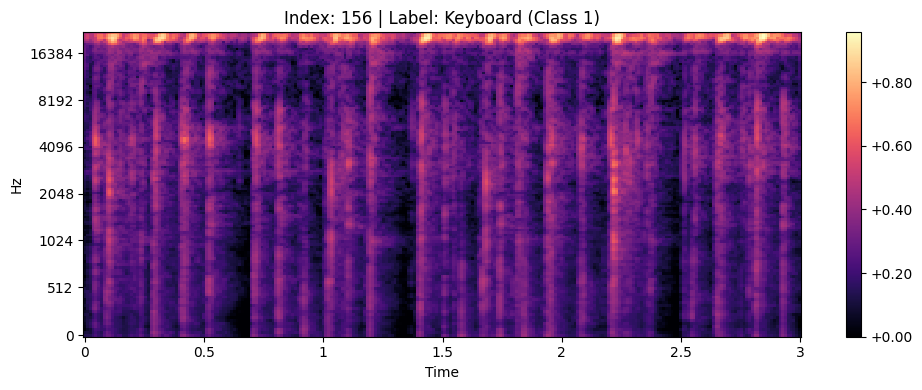

In [55]:
Example = 156

sample = x_train[Example]
label_data = y_train[Example]
class_index = np.argmax(label_data)
class_name = CATEGORIES[class_index]
plot_data = sample.squeeze()

plt.figure(figsize=(10, 4))
librosa.display.specshow(plot_data, 
                         sr=44100, 
                         hop_length=512, 
                         x_axis='time', 
                         y_axis='mel')

plt.colorbar(format='%+2.2f')
plt.title(f"Index: {Example} | Label: {class_name} (Class {class_index})")
plt.tight_layout()
plt.show()

## Network architecture

In [51]:
# Model definition (simplified & regularized)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

input_shape = x_train.shape[1:]  # (n_mels, time_steps, 1)

model = Sequential([
    # Conv Block 1
    Conv2D(16, (7,3), activation='relu', padding='same', input_shape=input_shape),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    
    # Conv Block 2
    Conv2D(32, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    
    # Conv Block 3
    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    GlobalAveragePooling2D(),  # reduces parameters and prevents overfitting
    
    # Dense + Output
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    
    Dense(len(CATEGORIES), activation='softmax')
])

# Use a smaller learning rate to stabilise training
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_29 (Conv2D)              │ (None, 128, 259, 16)   │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 128, 259, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 64, 129, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64, 129, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 64, 129, 32)    │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 64, 129, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 32, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 32, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 32, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,155 (129.51 KB)

 Trainable params: 32,675 (127.64 KB)

 Non-trainable params: 480 (1.88 KB)

## Model training

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step - accuracy: 0.4486 - loss: 1.2509
Epoch 1: val_loss improved from None to 1.09782, saving model to best_audio_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 385ms/step - accuracy: 0.4667 - loss: 1.1595 - val_accuracy: 0.3333 - val_loss: 1.0978
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.5044 - loss: 1.0134
Epoch 2: val_loss did not improve from 1.09782
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 357ms/step - accuracy: 0.4972 - loss: 1.0760 - val_accuracy: 0.3333 - val_loss: 1.0983
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - accuracy: 0.5378 - loss: 0.9715
Epoch 3: val_loss did not improve from 1.09782
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 354ms/step - accuracy: 0.5583 - loss: 1.0106 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - accuracy: 0.5161 - loss: 1.0263
Epoch 4: val_loss did not improve from 1.09782
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 350ms/step - accuracy: 0.5611 - loss: 0.96

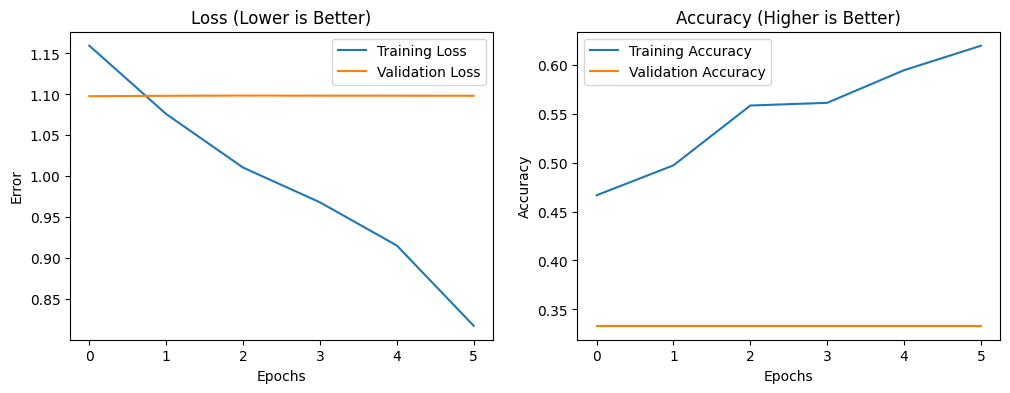

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 175ms/step


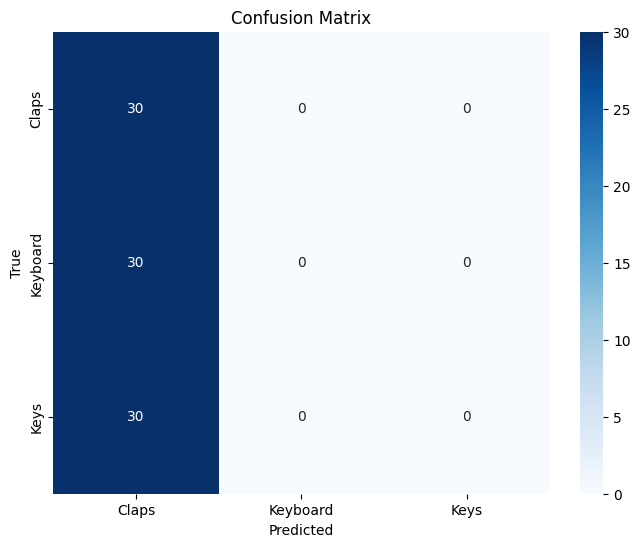

In [53]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. STOPPING: Stop if validation loss doesn't improve for 10 epochs (patience)
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, # reverts to the best epoch automatically
    verbose=1
)

# 2. SAVING: Save the best model to a file
checkpoint = ModelCheckpoint(
    'best_audio_model.keras', 
    monitor='val_loss', 
    save_best_only=True, 
    verbose=1
)

# 3. FITTING
history = model.fit(
    x_train, y_train,
    epochs=100,            # Set high, let EarlyStopping decide when to end
    batch_size=32,         # 32 is standard. For small data, 16 is also okay.
    validation_data=(x_test, y_test),
    callbacks=[checkpoint, early_stop]
)

import matplotlib.pyplot as plt

# 1. Plot the "Loss"
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1) # Left graph
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss (Lower is Better)')
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.legend()

# 2. Plot the "Accuracy"
plt.subplot(1, 2, 2) # Right graph
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy (Higher is Better)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

from sklearn.metrics import confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get the model's predictions (these will be probabilities)
predictions = model.predict(x_test)

# 2. Convert One-Hot Encoded labels back to Single Integers
# Example: [0, 1, 0] -> 1 (Keyboard)
y_pred_classes = np.argmax(predictions, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 4. (Optional) Plot a nice heatmap for the Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Live data Collection & Actuators 



In [ ]:
import pyaudio
import numpy as np
import librosa
import tensorflow as tf
import time
from IPython.display import clear_output

# --- Configuration ---
FORMAT = pyaudio.paInt16
CHANNELS = 1
RATE = 44100
CHUNK = 1024
RECORD_SECONDS = 3

# Spectrogram settings (128x259)
N_MELS = 128
HOP_LENGTH = 512
N_FFT = 2048

MODEL_PATH = "model.weights.h5"

# --- Load Model ---
try:
    print("Loading model...")
    model = tf.keras.models.load_model(MODEL_PATH)
    print("Model loaded.")
except Exception as e:
    print(f"Error loading model: {e}")
    exit()

# --- Audio Setup ---
audio = pyaudio.PyAudio()
stream = audio.open(format=FORMAT, channels=CHANNELS,
                    rate=RATE, input=True,
                    frames_per_buffer=CHUNK)

chunks_per_cycle = int(RATE / CHUNK * RECORD_SECONDS)

print("\n--- Starting Continuous Prediction Loop (0-1 Normalized) ---")

try:
    while True:
        print("Listening...", end="\r")
        
        # 1. Capture
        frames = []
        for i in range(0, chunks_per_cycle):
            data = stream.read(CHUNK, exception_on_overflow=False)
            frames.append(data)
        
        # 2. Process to Float
        audio_data = np.frombuffer(b''.join(frames), dtype=np.int16)
        audio_float = audio_data.astype(np.float32) / 32768.0
        
        # 3. Generate Mel Spectrogram (in dB)
        mel_spec = librosa.feature.melspectrogram(
            y=audio_float, sr=RATE, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP_LENGTH
        )
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        
        # --- 4. NORMALIZE TO [0, 1] ---
        # This scales the data so the quietest part is 0 and loudest is 1
        spec_min = np.min(mel_spec_db)
        spec_max = np.max(mel_spec_db)
        
        if spec_max - spec_min > 0:
            mel_spec_norm = (mel_spec_db - spec_min) / (spec_max - spec_min)
        else:
            mel_spec_norm = mel_spec_db # Handle silence
            
        # 5. Shape Enforcement (128x259)
        target_width = 259
        current_width = mel_spec_norm.shape[1]
        
        if current_width < target_width:
            padding = target_width - current_width
            mel_spec_norm = np.pad(mel_spec_norm, ((0, 0), (0, padding)))
        elif current_width > target_width:
            mel_spec_norm = mel_spec_norm[:, :target_width]
            
        # 6. Reshape and Predict
        # Input shape: (1, 128, 259, 1)
        input_data = np.expand_dims(mel_spec_norm, axis=0) 
        input_data = np.expand_dims(input_data, axis=-1) 
        
        prediction = model.predict(input_data, verbose=0)
        predicted_index = np.argmax(prediction)
        confidence = np.max(prediction)
        
        class_name = CATEGORIES[predicted_index]
        clear_output(wait=True)
        print(f"Prediction: Class {class_name} ({confidence:.2%} confidence)")

        plt.clf() # Clear previous plot
        
        # Visualize the normalized data entering the model
        librosa.display.specshow(mel_spec_norm, 
                                 sr=RATE, 
                                 hop_length=HOP_LENGTH, 
                                 x_axis='time', 
                                 y_axis='mel')
        
        plt.colorbar(format='%+2.2f')
        plt.title(f"Model Input: {class_name} ({confidence:.0%})")
        plt.tight_layout()
        plt.show()
        plt.close()
        

except KeyboardInterrupt:
    print("\nStopping...")
finally:
    stream.stop_stream()
    stream.close()
    audio.terminate()

Loading model...
Model loaded.

--- Starting Continuous Prediction Loop (0-1 Normalized) ---
Prediction: Class Claps (34.36% confidence)
Prediction: Class Claps (34.17% confidence)
Prediction: Class Claps (34.55% confidence)
Prediction: Class Claps (34.05% confidence)
Prediction: Class Claps (34.47% confidence)
Prediction: Class Claps (34.37% confidence)
Prediction: Class Claps (34.49% confidence)
Prediction: Class Claps (34.37% confidence)
Prediction: Class Claps (34.50% confidence)
Prediction: Class Claps (34.57% confidence)
Prediction: Class Claps (34.00% confidence)
Prediction: Class Claps (34.47% confidence)
Prediction: Class Claps (34.20% confidence)
Prediction: Class Claps (34.12% confidence)
Prediction: Class Claps (34.26% confidence)
Prediction: Class Claps (34.25% confidence)
Prediction: Class Claps (34.32% confidence)
Prediction: Class Claps (34.01% confidence)
Prediction: Class Claps (34.40% confidence)
Prediction: Class Claps (34.09% confidence)
Prediction: Class Claps (33

## Validation

You need the library "pyaudio" to test this feature.

    pip install pyaudio
    
    conda install conda-forge::pyaudio

In [ ]:
# import pyaudio
# import wave

# # Configuration parameters
# FORMAT = pyaudio.paInt16  # 16-bit resolution
# CHANNELS = 1              # Mono recording
# RATE = 44100              # Sample rate (44.1kHz is standard)
# CHUNK = 1024              # Buffer size
# RECORD_SECONDS = 5        # Duration of recording
# OUTPUT_FILENAME = "test_recording.wav"

# audio = pyaudio.PyAudio()

# # Start Recording
# stream = audio.open(format=FORMAT, channels=CHANNELS,
#                     rate=RATE, input=True,
#                     frames_per_buffer=CHUNK)

# print("Recording...")

# frames = []

# for i in range(0, int(RATE / CHUNK * RECORD_SECONDS)):
#     data = stream.read(CHUNK)
#     frames.append(data)

# print("Finished recording.")

# # Stop and close the stream
# stream.stop_stream()
# stream.close()
# audio.terminate()

# # Save the recorded data as a WAV file 
# # (THIS NEEDS TO BE CHANGED SO IT IS STORED IN MEMORY TO BE USED IN REAL TIME)
# with wave.open(OUTPUT_FILENAME, 'wb') as wf:
#     wf.setnchannels(CHANNELS)
#     wf.setsampwidth(audio.get_sample_size(FORMAT))
#     wf.setframerate(RATE)
#     wf.writeframes(b''.join(frames))

# print(f"File saved as {OUTPUT_FILENAME}")